In [1]:
import numpy as np
import pymc as pm
from arviz_plots import plot_ecdf_pit, style
import jax
import simuk
import jax
import numpyro
import numpy as np
import numpyro.distributions as dist
from arviz_plots import plot_ecdf_pit
from numpyro.infer import NUTS, MCMC, Predictive
import simuk
import arviz as az
import pymc as pm

random_seed = 42
rng = np.random.default_rng(random_seed)
style.use("arviz-variat")

In [2]:
def simple_bivariate_normal_model(y=None):
    # See section 4.1 of https://arxiv.org/abs/2211.02383
    sigma = np.array([[1, 0.8], [0.8, 1]])
    mu = numpyro.sample("mu", dist.MultivariateNormal(loc=np.array([0.,0.]), covariance_matrix=sigma))
    numpyro.sample("y", dist.MultivariateNormal(loc=mu, covariance_matrix=sigma), obs=y)


In [3]:
rng_key = jax.random.PRNGKey(0)

nuts_kernel = NUTS(simple_bivariate_normal_model)
mcmc = MCMC(nuts_kernel, num_warmup=100, num_samples=1000)

obs_data = np.array([[2,3], [3,4], [5,6]])

mcmc.run(rng_key=rng_key, y=obs_data)

trace = mcmc.get_samples(group_by_chain=True)

sample: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1100/1100 [00:00<00:00, 1476.08it/s, 3 steps of size 4.50e-01. acc. prob=0.93]


In [4]:
dt = az.from_dict(
    {
        "posterior": trace,
        "observed_data": {"y": obs_data},
    },
    dims={"mu": ["chain", "draw"], "y": ["observation_idx"]},
    coords={"y": 20},
    sample_dims=["chain", "draw"]
)

In [5]:
sbc_numpyro = simuk.SBC(
    nuts_kernel,
    method="posterior",
    trace= dt,
    data_dir = {"y": obs_data},
    num_simulations=50,
)
sbc_numpyro.run_simulations()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:46<00:00,  1.07it/s]


In [6]:
obs_data

array([[2, 3],
       [3, 4],
       [5, 6]])

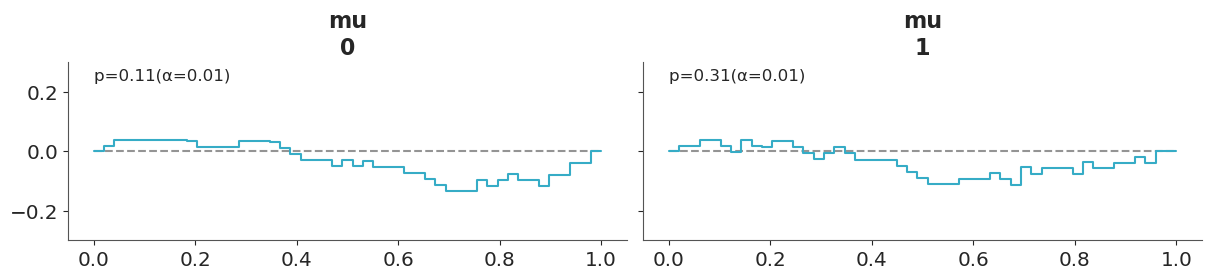

In [7]:
plot_ecdf_pit(
    sbc_numpyro.simulations,
    group="posterior_sbc",
    visuals={"xlabel": False},
);

In [8]:
sbc_numpyro.simulations

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:           numpyro
│       inference_library_version:   0.22.0
│       modeling_interface:          simuk
│       modeling_interface_version:  TODO ROLLBACK
└── Group: /posterior_sbc
        Dimensions:   (chain: 1, draw: 50, mu_dim_0: 2)
        Coordinates:
          * chain     (chain) int64 8B 0
          * draw      (draw) int64 400B 0 1 2 3 4 5 6 7 8 ... 41 42 43 44 45 46 47 48 49
          * mu_dim_0  (mu_dim_0) int64 16B 0 1
        Data variables:
            mu        (chain, draw, mu_dim_0) int64 800B 491 220 825 143 ... 71 293 326
        Attributes:
            created_at:                 2026-10-13T22:01:33.937465+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.1
            creation_library_language:  Python
            sample_dims:                ['chain', 'draw']